```{index} single: Pyomo; block
```
```{index} single: Pyomo; sets
```
```{index} single: Pyomo; parameters
```
```{index} single: solver; HiGHS
```
```{index} single: application; production planning
```
```{index} pandas dataframe
```

# 3.7 BIM production revisited

## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it 
assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null

solver = "appsi_highs"

import pyomo.environ as pyo

SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

## Problem description

We consider again the [BIM raw material planning problem](../02/07-bim-demand-forecast.ipynb) from Chapter 2 but with more sophisticated pricing and acquisition protocols. There are now three suppliers, each of which can deliver the following materials:
 - A: **silicon**, **germanium** and **plastic**
 - B: **copper**
 - C: all the above
 
For the suppliers, the following conditions apply: copper should be acquired in multiples of 100 g, since it is delivered in sheets of that weight. Unitary materials such as silicon, germanium and plastic may be acquired in any number, but the price is in batches of 100. For example, 30 units of silicon with 10 units of germanium and 50 units of plastic cost as much as 1 unit of silicon but half as much as 30 units of silicon with 30 units of germanium and 50 units of plastic. Furthermore, supplier C sells all materials and offers a discount if purchased together: 100 g of copper and a batch of unitary material cost only 7. This set price is only applied to pairs, meaning that 100 g of copper and 2 batches cost 13.

The summary of the prices in dollars is given in the following table:

<div align="center">

|Supplier|Copper per sheet of 100 g|     Batches|Together|
|:-------|---------------------:|-----------------:|-------:|
| A      |                    - |                5 |      - |
| B      |                    3 |                - |      - |
| C      |                    4 |                6 |      7 |

</div>

Holding costs are charged on month-end stocks. The following table gives the costs in dollars per month:

<div align="center">

|Copper per 10 g| Silicon per unit| Germanium per unit|Plastic per unit|
|---:|-------:|---:|-----:|
| 0.1|   0.02 |0.02| 0.02 |

</div>

The holding price of copper is per 10 g and the copper stocked is rounded up to multiples of 10 g, meaning that 12 g are charged as 20 g. The capacity limitations of the warehouse allow for a maximum of $10$ kilograms of copper in stock at the end of each month, but there are no practical limitations to the number of units of unitary products in stock. The production is made-to-order, meaning that no inventory of chips is kept.

Copper stock quantities are measured in grams, as in the linked Chapter 2 example; the other material quantities are in units. Recall that BIM has the following stock at the beginning of the year:

<div align="center">

|Copper (g) |Silicon (units) |Germanium (units) |Plastic (units)|
|---:|-------:|---:|-----:|
| 4800|   1000 |1500| 1750 |

</div>

The company would like to have at least the following stock at the end of the year:

<div align="center">

|Copper (g) |Silicon (units) |Germanium (units) |Plastic (units)|
|---:|-------:|---:|-----:|
| 2000|    500 | 500| 1000 |

</div>

The goal is to build an optimization model using the data above and solve it to minimize the acquisition and holding costs of the products while meeting the required quantities for production. 


## Data import

In the next cell we import and store the data described in dictionaries or Pandas dataframes.

In [2]:
from io import StringIO
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

demand_data = """
chip, Jan, Feb, Mar, Apr, May, Jun, Jul, Aug, Sep, Oct, Nov, Dec
logic, 88, 125, 260, 217, 238, 286, 248, 238, 265, 293, 259, 244
memory, 47, 62, 81, 65, 95, 118, 86, 89, 82, 82, 84, 66
"""

demand_chips = pd.read_csv(StringIO(demand_data), index_col="chip")
display(demand_chips)

use = dict()
use["logic"] = {"silicon": 1, "plastic": 1, "copper": 4}
use["memory"] = {"germanium": 1, "plastic": 1, "copper": 2}
use = pd.DataFrame.from_dict(use).fillna(0).astype(int)
display(use)

demand = use.dot(demand_chips)
display(demand)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
chip,,,,,,,,,,,,
logic,88,125,260,217,238,286,248,238,265,293,259,244
memory,47,62,81,65,95,118,86,89,82,82,84,66


,logic,memory
silicon,1,0
plastic,1,1
copper,4,2
germanium,0,1


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,88,125,260,217,238,286,248,238,265,293,259,244
plastic,135,187,341,282,333,404,334,327,347,375,343,310
copper,446,624,1202,998,1142,1380,1164,1130,1224,1336,1204,1108
germanium,47,62,81,65,95,118,86,89,82,82,84,66


## Optimization model

As usual, we need to start modeling by naming our decisions and identifying the relevant index sets. In the [previous BIM notebook](../02/07-bim-demand-forecast.ipynb) we already had a set $T$ of time periods (i.e., the months) and a set $P$ for the products. Since we want to keep track of how much we buy for which material and from which supplier, we need an additional index set $S$ for the suppliers. Write $S_u=\{A,C\}$ for the suppliers of unitary materials and $S_c=\{B,C\}$ for the suppliers of copper sheets.

In the [previous BIM notebook](../02/07-bim-demand-forecast.ipynb) all decision variables were continuous, but now we also need to take care of a number of integer decision variables:

- number of batches of the unitary products;
- number of copper sheets;
- number of 10 g copper stock buckets;
- number of copper sheet-batch of unitary product pairs acquired in the same month from supplier C, yielding discount.

Given the above, we can clearly reuse the variables $s_{pt}$ from [previous BIM notebook](../02/07-bim-demand-forecast.ipynb) to denote the month-end stock of each product, in grams for copper and units for the other materials. Write $\delta_{pt}$ for the material requirements in month $t$ and $\Omega_p$ for the minimum stock required at the end of December. With respect to purchasing variables, however, we now need to keep track of unitary products and suppliers. For this reason, we introduce the integer variables $y_{ts}$ for the number of copper sheets purchased from supplier $s$, and continuous variables $x_{pts}$ for the number of units of unitary product $p$ purchased from supplier $s$. To translate these variables into the total amounts of a product purchased regardless of supplier, we introduce another variable $u_{pt}$.

Further, we introduce the variables that we use to account for the tricky integer quantities in our model. To account for the number of batches of unitary products at supplier $s$, we introduce integer variables $b_{ts}$, and, similarly, we introduce an integer variable $r_t$ for the number of 10 g copper stock buckets in the inventory. Buying a copper sheet together with a batch of unitary products from supplier C is advantageous as we get a discount of $4+6-7=3$ dollars, or $\beta=300$ cents. For this reason, we introduce an extra integer variable $p_t$ to count the number of such pairs, so that $\beta p_t$ is the total discount in month $t$. We need to include additional constraints to make sure that these three variables account for batches, stock buckets and discounted pairs in relation to the purchasing and inventory variables.

Taking all the above into account, we shall use the following decision variables:

- $y_{ts}$: number of sheets of copper purchased in month $t$ from supplier $s$
- $x_{pts}$: number of units of unitary product $p$ purchased in month $t$ from supplier $s$
- $u_{pt}$: total number of units of product $p$ purchased in month $t$ (from all suppliers combined)
- $b_{ts}$: number of batches of 100 unitary products purchased in month $t$ from supplier $s$
- $p_{t}$: number of batch-copper sheet pairs purchased in month $t$ from supplier C 
- $r_t$: number of 10 g copper stock buckets (rounded up) in month $t$.

We formulate all costs below in cents. Let $\pi_s$ be the price per batch of unitary materials and $\alpha_s$ the price per copper sheet. Thus $\pi_A=500$, $\pi_C=600$, $\alpha_B=300$, $\alpha_C=400$ and $\beta=300$. Let $\gamma_{\text{copper}}=10$ be the holding cost per 10 g stock bucket and $\gamma_p=2$ the holding cost per unit of each other material. In the code, the copper-sheet price $\alpha_s$ is `m.kappa[s]`; `m.Alpha[p]` instead denotes the given initial stock. The total material acquisition cost is

$$
\begin{equation*}
    \sum_{t \in T} \Big( \sum_{s \in S_u} \pi_{s} b_{ts} + \sum_{s \in S_c} \alpha_{s} y_{ts} - \beta p_t \Big),
\end{equation*}
$$

where we count the acquisition costs for supplier $C$ as the total cost of the sheets of copper plus the batches of unitary materials minus the discount due to purchasing the pairs:

$$
\begin{equation*}
    \pi_{\text{C}} b_{t, \text{C}} + \alpha_{\text{C}} y_{t, \text{C}}  - \beta p_t.
\end{equation*}
$$

The total inventory cost is

$$
\begin{equation*}
    \sum_{t \in T} \Big( \gamma_{\text{copper}} r_t + \sum_{p \in P \setminus\{\text{copper}\}} \gamma_p s_{pt} \Big).
\end{equation*}
$$

Now, we need to construct a system of constraints to ensure that the above costs are computed correctly. To transform the amounts of unitary materials purchased into batches of $100$, we construct the following constraints:

$$
\begin{equation*}
    \sum_{p \in P \setminus\{\text{copper}\}}  x_{pts} \leq 100 b_{ts}.
\end{equation*}
$$

Because the inventory costs for copper are computed by rounding up to 10 g amounts, we account for this via the following constraint

$$
\begin{equation*}
    s_{\text{copper}, t} \leq 10 r_t.
\end{equation*}
$$

To count the discounted pairs purchased from supplier C, impose the following constraints:

$$
\begin{equation*}
    p_t \leq b_{t,\text{C}}, \quad \text{ and } \quad p_t \leq y_{t, \text{C}}.
\end{equation*}
$$

Choosing the maximum possible amount $p_t$ that satisfies such constraints will naturally lead to maximizing the number of pairs and, thus, the total discount.

Adding the material balances, copper storage capacity and final-stock requirements gives the following formulation:

$$
\begin{align*}
    \min \quad & \sum_{t \in T} \Big( \sum_{s \in S_u} \pi_{s} b_{ts} + \sum_{s \in S_c} \alpha_{s} y_{ts} - \beta p_t \Big) +
    \sum_{t \in T} \Big (  \gamma_{\text{copper}} r_t + \sum_{p \in P \setminus \{ \text{copper}\}} \gamma_{p} s_{pt}  \Big) \\
    \text{s.t.} \quad 
    & \sum_{p \in P \setminus \{ \text{copper}\}} x_{pts} \leq 100 \cdot b_{ts} & \forall \, t \in T, \, \forall \, s \in S_u\\
    & s_{\text{copper}, t} \leq 10 \cdot r_t & \forall \, t \in T\\
    & s_{\text{copper}, t} \leq 10000 & \forall \, t \in T\\
    & u_{\text{copper}, t} = 100 \sum_{s \in S_c} y_{ts} & \forall \, t \in T\\
    & p_t \leq b_{t,\text{C}}, \quad p_t \leq y_{t, \text{C}} & \forall \, t \in T \\
    & u_{pt} = \sum_{s \in S_u} x_{pts} & \forall \, t \in T, \, \forall \, p \in P \setminus \{ \text{copper}\}\\
    & s_{p,t-1} + u_{p,t} = \delta_{pt} + s_{pt} & \forall \, t \in T, \, \forall p \in P\\ 
    & s_{p,\textrm{Dec}} \geq \Omega_p &  \forall \, p \in P \\
    & b_{ts} \in \mathbb{Z}_{+} & \forall \, t \in T, \, s \in S_u \\
    & y_{ts} \in \mathbb{Z}_{+} & \forall \, t \in T, \, s \in S_c \\
    & r_t, p_t \in \mathbb{Z}_{+} & \forall \, t \in T \\
    & x_{pts} \geq 0 & \forall \, p \in P\setminus\{\text{copper}\}, \, t \in T, \, s \in S_u \\
    & u_{pt}, s_{pt} \geq 0 & \forall \, p \in P, \, t \in T.
\end{align*}
$$

For January, $s_{p,t-1}$ denotes the given initial stock. In every later month, it is the preceding month-end stock decision. The copper capacity constraint applies at month end. The discount term is $-\beta p_t$, with $\beta>0$, so for fixed sheet and batch purchases it is optimal to use the maximum allowed number of pairs. Positive holding costs make $r_t$ the smallest integer covering the copper stock. For the stated prices, an additional supplier-C batch costs $600$ cents and can add at most $300$ cents of discount, so unnecessary extra batches do not reduce the cost.

## Pyomo implementation

In the next cell, we implement the model described above in Pyomo using a function that can take the data as input arguments, so we can then easily use it with different data.

In [3]:
def BIMproduction_v1(
    demand,
    existing,
    desired,
    stock_limit,
    supplying_copper,
    supplying_batches,
    price_copper_sheet,
    price_batch,
    discounted_price,
    batch_size,
    copper_sheet_mass,
    copper_bucket_size,
    unitary_products,
    unitary_holding_costs,
):
    m = pyo.ConcreteModel(
        "BIM product acquisition and inventory with sophisticated prices"
    )

    periods = demand.columns
    products = demand.index
    first = periods[0]
    prev = {j: i for i, j in zip(periods, periods[1:])}
    last = periods[-1]

    @m.Param(products, periods)
    def delta(m, p, t):
        return demand.loc[p, t]

    @m.Param(supplying_batches)
    def pi(m, s):
        return price_batch[s]

    @m.Param(supplying_copper)
    def kappa(m, s):
        return price_copper_sheet[s]

    @m.Param()
    def beta(m):
        return price_batch["C"] + price_copper_sheet["C"] - discounted_price

    @m.Param(products)
    def gamma(m, p):
        return unitary_holding_costs[p]

    @m.Param(products)
    def Alpha(m, p):
        return existing[p]

    @m.Param(products)
    def Omega(m, p):
        return desired[p]

    m.y = pyo.Var(periods, supplying_copper, domain=pyo.NonNegativeIntegers)
    m.x = pyo.Var(
        unitary_products, periods, supplying_batches, domain=pyo.NonNegativeReals
    )
    m.s = pyo.Var(products, periods, domain=pyo.NonNegativeReals)
    m.u = pyo.Var(products, periods, domain=pyo.NonNegativeReals)
    m.b = pyo.Var(periods, supplying_batches, domain=pyo.NonNegativeIntegers)
    m.p = pyo.Var(periods, domain=pyo.NonNegativeIntegers)
    m.r = pyo.Var(periods, domain=pyo.NonNegativeIntegers)

    @m.Constraint(periods, supplying_batches)
    def units_in_batches(m, t, s):
        return (
            pyo.quicksum(m.x[p, t, s] for p in unitary_products)
            <= batch_size * m.b[t, s]
        )

    @m.Constraint(periods)
    def copper_in_buckets(m, t):
        return m.s["copper", t] <= copper_bucket_size * m.r[t]

    @m.Constraint(periods)
    def inventory_capacity(m, t):
        return m.s["copper", t] <= stock_limit

    @m.Constraint(periods)
    def pairs_in_batches(m, t):
        return m.p[t] <= m.b[t, "C"]

    @m.Constraint(periods)
    def pairs_in_sheets(m, t):
        return m.p[t] <= m.y[t, "C"]

    @m.Constraint(periods, products)
    def bought(m, t, p):
        if p == "copper":
            return m.u[p, t] == copper_sheet_mass * pyo.quicksum(
                m.y[t, s] for s in supplying_copper
            )
        else:
            return m.u[p, t] == pyo.quicksum(m.x[p, t, s] for s in supplying_batches)

    @m.Expression()
    def acquisition_cost(m):
        return pyo.quicksum(
            pyo.quicksum(m.pi[s] * m.b[t, s] for s in supplying_batches)
            + pyo.quicksum(m.kappa[s] * m.y[t, s] for s in supplying_copper)
            - m.beta * m.p[t]
            for t in periods
        )

    @m.Expression()
    def inventory_cost(m):
        return pyo.quicksum(
            m.gamma["copper"] * m.r[t]
            + pyo.quicksum(m.gamma[p] * m.s[p, t] for p in unitary_products)
            for t in periods
        )

    @m.Objective(sense=pyo.minimize)
    def total_cost(m):
        return m.acquisition_cost + m.inventory_cost

    @m.Constraint(products, periods)
    def balance(m, p, t):
        if t == first:
            return m.Alpha[p] + m.u[p, t] == m.delta[p, t] + m.s[p, t]
        else:
            return m.u[p, t] + m.s[p, prev[t]] == m.delta[p, t] + m.s[p, t]

    @m.Constraint(products)
    def finish(m, p):
        return m.s[p, last] >= m.Omega[p]

    return m

We then solve the model using the provided data. We introduce three auxiliary functions to more quickly parse the output of the model and use them to report the solution as a set of Pandas dataframes and visualize the monthly stock levels.

The tables round quantities to three decimal places for display, retaining fractional purchases and stock levels. The optimization uses the unrounded values.


Optimal cost is 110216 cents, that is $1102.16

Monthly purchased material


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,0.0,0.0,0.0,0.0,0.0,229.0,233.0,238.0,265.0,349.0,203.0,744.0
plastic,0.0,0.0,0.0,0.0,0.0,0.0,267.0,362.0,335.0,351.0,397.0,1256.0
copper,0.0,0.0,0.0,0.0,0.0,1000.0,1200.0,1100.0,1300.0,1300.0,1200.0,3100.0
germanium,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Acquisition plan for copper sheet and batch pairs from supplier C


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,0.0,0.0,0.0,0.0,0.0,3.0,5.0,6.0,6.0,7.0,6.0,20.0


Copper sheet purchases by supplier


...

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C,0.0,0.0,0.0,0.0,0.0,3.0,5.0,6.0,6.0,7.0,6.0,20.0


Acquisition plan for unitary materials (quantities)


Jan  Feb  Mar  Apr  May    Jun    Jul    Aug    Sep  \
supplier materials                                                        
A        silicon    0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
         germanium  0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
         plastic    0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
C        silicon    0.0  0.0  0.0  0.0  0.0  229.0  233.0  238.0  265.0   
         germanium  0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
         plastic    0.0  0.0  0.0  0.0  0.0    0.0  267.0  362.0  335.0   

                      Oct    Nov     Dec  
supplier materials                        
A        silicon      0.0    0.0     0.0  
         germanium    0.0    0.0     0.0  
         plastic      0.0    0.0     0.0  
C        silicon    349.0  203.0   744.0  
         germanium    0.0    0.0     0.0  
         plastic    351.0  397.0  1256.0

The stock levels at the end of each month resulting from the optimal acquisition and production plan


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,912.0,787.0,527.0,310.0,72.0,15.0,0.0,0.0,0.0,56.0,0.0,500.0
plastic,1615.0,1428.0,1087.0,805.0,472.0,68.0,1.0,36.0,24.0,0.0,54.0,1000.0
copper,4354.0,3730.0,2528.0,1530.0,388.0,8.0,44.0,14.0,90.0,54.0,50.0,2042.0
germanium,1453.0,1391.0,1310.0,1245.0,1150.0,1032.0,946.0,857.0,775.0,693.0,609.0,543.0


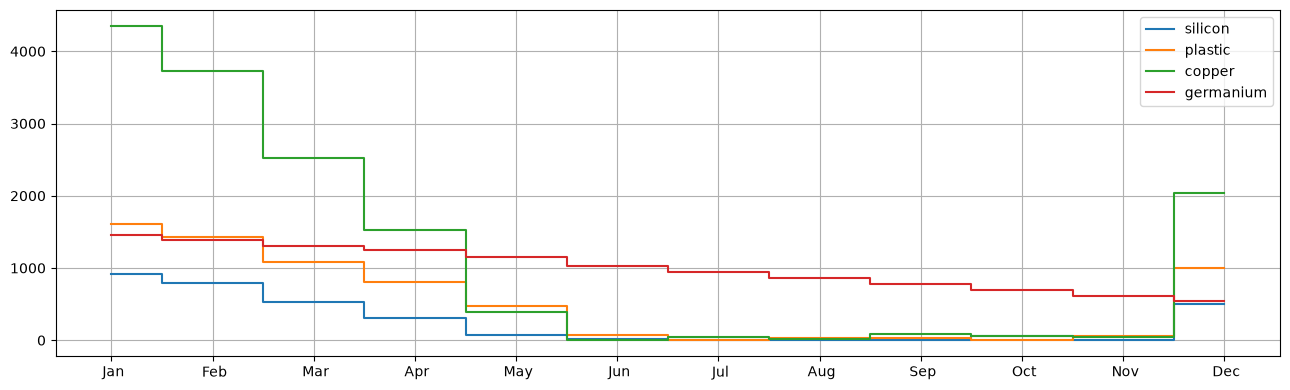

In [4]:
def Table1d(m, J, retriever):
    return pd.DataFrame([retriever(m, j) for j in J], index=J).T.round(3) + 0.0


def Table2d(m, I, J, retriever):
    return pd.DataFrame.from_records(
        [[retriever(m, i, j) for j in J] for i in I], index=I, columns=J
    ).round(3) + 0.0


def Table3d(m, I, J, names, K, retriever):
    index = pd.MultiIndex.from_product([I, J], names=names)
    return pd.DataFrame.from_records(
        [[retriever(m, i, j, k) for k in K] for i in I for j in J],
        index=index,
        columns=K,
    ).round(3) + 0.0


m1 = BIMproduction_v1(
    demand=demand,
    existing={"silicon": 1000, "germanium": 1500, "plastic": 1750, "copper": 4800},
    desired={"silicon": 500, "germanium": 500, "plastic": 1000, "copper": 2000},
    stock_limit=10000,
    supplying_copper=["B", "C"],
    supplying_batches=["A", "C"],
    price_copper_sheet={"B": 300, "C": 400},
    price_batch={"A": 500, "C": 600},
    discounted_price=700,
    batch_size=100,
    copper_sheet_mass=100,
    copper_bucket_size=10,
    unitary_products=["silicon", "germanium", "plastic"],
    unitary_holding_costs={"copper": 10, "silicon": 2, "germanium": 2, "plastic": 2},
)
# Compare the implementations using fully closed relative MIP gaps.
SOLVER.options["mip_rel_gap"] = 0
results = SOLVER.solve(m1)
pyo.assert_optimal_termination(results)
print(
    f"Optimal cost is {pyo.value(m1.total_cost):.0f} cents, that is ${pyo.value(m1.total_cost) / 100:.2f}\n"
)

print("Monthly purchased material")
display(Table2d(m1, demand.index, demand.columns, lambda m, i, j: pyo.value(m.u[i, j])))

print("Acquisition plan for copper sheet and batch pairs from supplier C")
display(Table1d(m1, J=demand.columns, retriever=lambda m, j: pyo.value(m.p[j])))

print("Copper sheet purchases by supplier")
display(Table2d(m1, ["B", "C"], demand.columns, lambda m, i, j: pyo.value(m.y[j, i])))

print("Acquisition plan for unitary materials (batches)")
display(Table2d(m1, ["A", "C"], demand.columns, lambda m, i, j: pyo.value(m.b[j, i])))

print("Acquisition plan for unitary materials (quantities)")
display(
    Table3d(
        m1,
        I=["A", "C"],
        J=["silicon", "germanium", "plastic"],
        names=["supplier", "materials"],
        K=demand.columns,
        retriever=lambda m, i, j, k: 0 + pyo.value(m.x[j, k, i]),
    )
)

print(
    "The stock levels at the end of each month resulting from the optimal acquisition and production plan"
)
stock = Table2d(m1, demand.index, demand.columns, lambda m, i, j: pyo.value(m.s[i, j]))
display(stock)
stock.T.plot(drawstyle="steps-mid", grid=True, figsize=(13, 4))
plt.xticks(np.arange(len(stock.columns)), stock.columns)
plt.tight_layout()
plt.show()

## Alternative Pyomo implementation using blocks

In the next cell, we implement a second version of the same model, which is equivalent to the previous one, but uses Pyomo sets and block components to iterate over all the time indices.

In [5]:
def BIMproduction_v2(
    demand,
    existing,
    desired,
    stock_limit,
    supplying_copper,
    supplying_batches,
    price_copper_sheet,
    price_batch,
    discounted_price,
    batch_size,
    copper_sheet_mass,
    copper_bucket_size,
    unitary_products,
    unitary_holding_costs,
):
    m = pyo.ConcreteModel(
        "BIM product acquisition and inventory with sophisticated prices (using blocks)"
    )

    periods = demand.columns
    products = demand.index
    first = periods[0]
    prev = {j: i for i, j in zip(periods, periods[1:])}
    last = periods[-1]

    m.T = pyo.Set(initialize=periods)
    m.P = pyo.Set(initialize=products)

    m.PT = m.P * m.T  # to avoid internal set bloat

    @m.Block(m.T)
    def A(b):
        b.x = pyo.Var(supplying_batches, unitary_products, domain=pyo.NonNegativeReals)
        b.b = pyo.Var(supplying_batches, domain=pyo.NonNegativeIntegers)
        b.y = pyo.Var(supplying_copper, domain=pyo.NonNegativeIntegers)
        b.p = pyo.Var(domain=pyo.NonNegativeIntegers)

        @b.Constraint(supplying_batches)
        def in_batches(b, s):
            return pyo.quicksum(b.x[s, p] for p in unitary_products) <= batch_size * b.b[s]

        @b.Constraint()
        def pairs_in_batches(b):
            return b.p <= b.b["C"]

        @b.Constraint()
        def pairs_in_sheets(b):
            return b.p <= b.y["C"]

        @b.Expression(products)
        def u(b, p):
            if p == "copper":
                return copper_sheet_mass * pyo.quicksum(
                    b.y[s] for s in supplying_copper
                )
            return pyo.quicksum(b.x[s, p] for s in supplying_batches)

        @b.Expression()
        def cost(b):
            discount = price_batch["C"] + price_copper_sheet["C"] - discounted_price
            return (
                pyo.quicksum(price_copper_sheet[s] * b.y[s] for s in supplying_copper)
                + pyo.quicksum(price_batch[s] * b.b[s] for s in supplying_batches)
                - discount * b.p
            )

    @m.Block(m.T)
    def I(b):
        b.s = pyo.Var(products, domain=pyo.NonNegativeReals)
        b.r = pyo.Var(domain=pyo.NonNegativeIntegers)

        @b.Constraint()
        def copper_in_buckets(b):
            return b.s["copper"] <= copper_bucket_size * b.r

        @b.Constraint()
        def capacity(b):
            return b.s["copper"] <= stock_limit

        @b.Expression()
        def cost(b):
            return unitary_holding_costs["copper"] * b.r + pyo.quicksum(
                unitary_holding_costs[p] * b.s[p] for p in unitary_products
            )

    @m.Param(m.PT)
    def delta(m, p, t):
        return demand.loc[p, t]

    @m.Expression()
    def acquisition_cost(m):
        return pyo.quicksum(m.A[t].cost for t in m.T)

    @m.Expression()
    def inventory_cost(m):
        return pyo.quicksum(m.I[t].cost for t in m.T)

    @m.Objective(sense=pyo.minimize)
    def total_cost(m):
        return m.acquisition_cost + m.inventory_cost

    @m.Constraint(m.PT)
    def balance(m, p, t):
        if t == first:
            return existing[p] + m.A[t].u[p] == m.delta[p, t] + m.I[t].s[p]
        else:
            return m.A[t].u[p] + m.I[prev[t]].s[p] == m.delta[p, t] + m.I[t].s[p]

    @m.Constraint(m.P)
    def finish(m, p):
        return m.I[last].s[p] >= desired[p]

    return m

We can then pass the parameters and data to this Pyomo model and solve it, as illustrated in the following code cell. We report the solution as a set of Pandas dataframes and visualize the monthly stock levels.

Optimal cost is 110216 cents, that is $1102.16

Acquisition plan for unitary materials (quantities)


Jan  Feb  Mar  Apr  May    Jun    Jul    Aug    Sep  \
supplier materials                                                        
A        silicon    0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
         germanium  0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
         plastic    0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
C        silicon    0.0  0.0  0.0  0.0  0.0  214.0  248.0  274.0  229.0   
         germanium  0.0  0.0  0.0  0.0  0.0    0.0    0.0    0.0    0.0   
         plastic    0.0  0.0  0.0  0.0  0.0   15.0  252.0  326.0  371.0   

                      Oct    Nov     Dec  
supplier materials                        
A        silicon      0.0    0.0     0.0  
         germanium    0.0    0.0     0.0  
         plastic      0.0    0.0     0.0  
C        silicon    349.0  257.0   690.0  
         germanium    0.0    0.0     0.0  
         plastic    351.0  343.0  1310.0

The stock levels at the end of each month resulting from the optimal acquisition and production plan


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
silicon,912.0,787.0,527.0,310.0,72.0,0.0,0.0,36.0,0.0,56.0,54.0,500.0
plastic,1615.0,1428.0,1087.0,805.0,472.0,83.0,1.0,0.0,24.0,0.0,0.0,1000.0
copper,4354.0,3730.0,2528.0,1530.0,388.0,8.0,44.0,14.0,90.0,54.0,50.0,2042.0
germanium,1453.0,1391.0,1310.0,1245.0,1150.0,1032.0,946.0,857.0,775.0,693.0,609.0,543.0


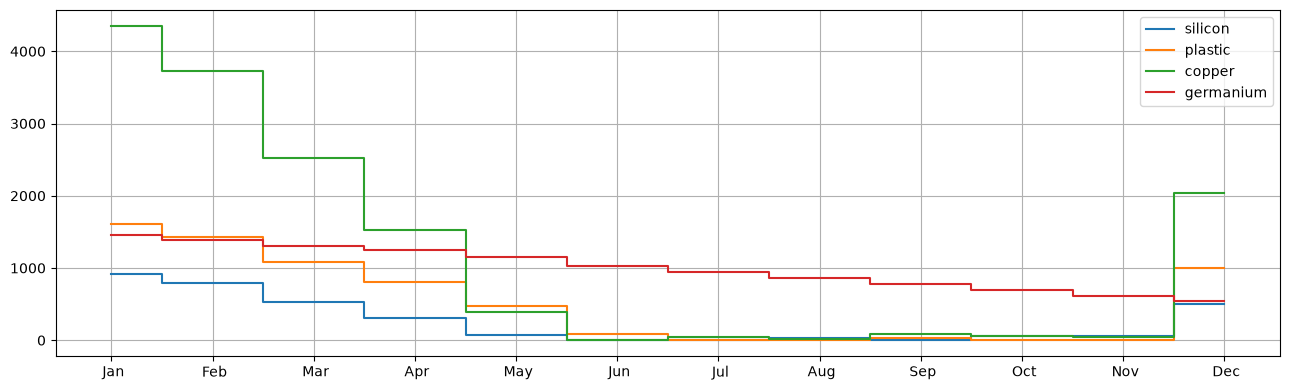

In [6]:
m2 = BIMproduction_v2(
    demand=demand,
    existing={"silicon": 1000, "germanium": 1500, "plastic": 1750, "copper": 4800},
    desired={"silicon": 500, "germanium": 500, "plastic": 1000, "copper": 2000},
    stock_limit=10000,
    supplying_copper=["B", "C"],
    supplying_batches=["A", "C"],
    price_copper_sheet={"B": 300, "C": 400},
    price_batch={"A": 500, "C": 600},
    discounted_price=700,
    batch_size=100,
    copper_sheet_mass=100,
    copper_bucket_size=10,
    unitary_products=["silicon", "germanium", "plastic"],
    unitary_holding_costs={"copper": 10, "silicon": 2, "germanium": 2, "plastic": 2},
)
results = SOLVER.solve(m2)
pyo.assert_optimal_termination(results)
assert abs(pyo.value(m1.total_cost) - pyo.value(m2.total_cost)) <= 1e-4
print(
    f"Optimal cost is {pyo.value(m2.total_cost):.0f} cents, that is ${pyo.value(m2.total_cost) / 100:.2f}\n"
)

print("Acquisition plan for unitary materials (quantities)")
display(
    Table3d(
        m2,
        I=["A", "C"],
        J=["silicon", "germanium", "plastic"],
        names=["supplier", "materials"],
        K=m2.T,
        retriever=lambda m, i, j, k: 0 + pyo.value(m.A[k].x[i, j]),
    )
)

print(
    "The stock levels at the end of each month resulting from the optimal acquisition and production plan"
)
stock = Table2d(m2, I=m2.P, J=m2.T, retriever=lambda m, i, j: pyo.value(m.I[j].s[i]))
display(stock)
stock.T.plot(drawstyle="steps-mid", grid=True, figsize=(13, 4))
plt.xticks(np.arange(len(stock.columns)), stock.columns)
plt.tight_layout()
plt.show()

Both implementations attain the same optimal cost; monthly purchases and stocks can differ because the optimal solution is not unique.